In [1]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
class AgentState(TypedDict):
  number1: int
  operator1: str
  number2: int
  number3:int
  operator2: str
  number4:int
  finalNumber1: int
  finalNumber2: int

In [15]:
def adder1(state: AgentState) -> AgentState:
  """ Simple function to add 2 numbers """
  state["finalNumber1"] = state["number1"]+ state["number2"]
  return state

def subtractor1(state: AgentState) -> AgentState:
  """ Simple function to subtract 2 numbers """
  state["finalNumber1"] = state["number1"]- state["number2"]
  return state

def router1(state: AgentState) -> AgentState:
  """ Simple function to route based on operator """
  if state["operator1"] =="sum":
    return "to_addition_node1"
  else: 
    return "to_subtraction_node1"

def adder2(state: AgentState) -> AgentState:
  """ Simple function to add 2 numbers """
  state["finalNumber2"] = state["number3"]+ state["number4"]
  return state

def subtractor2(state: AgentState) -> AgentState:
  """ Simple function to subtract 2 numbers """
  state["finalNumber2"]= state["number3"]- state["number4"]
  return state

def router2(state: AgentState) -> AgentState:
  """ Simple function to route based on the operator """
  if state["operator2"] == "sum":
    return "to_addition_node2"
  else: 
    return "to_subtraction_node2"
  


In [16]:
graph = StateGraph(AgentState)
graph.add_node("addition_node1", adder1)
graph.add_node("subtraction_node1", subtractor1)
graph.add_node("Router1", lambda state:state)
graph.add_node("addition_node2", adder2)
graph.add_node("subtraction_node2", subtractor2)
graph.add_node("Router2", lambda state:state)

graph.add_edge(START, "Router1")
graph.add_conditional_edges(
  "Router1",
  router1,
  {
    "to_addition_node1": "addition_node1",
    "to_subtraction_node1": "subtraction_node1"
  }
)

graph.add_edge("addition_node1", "Router2")
graph.add_edge("subtraction_node1", "Router2")

graph.add_conditional_edges(
  "Router2",
  router2,
  {
    "to_addition_node2": "addition_node2",
    "to_subtraction_node2": "subtraction_node2"
  }
)
graph.add_edge("addition_node2", END)
graph.add_edge("subtraction_node2", END)

app = graph.compile()

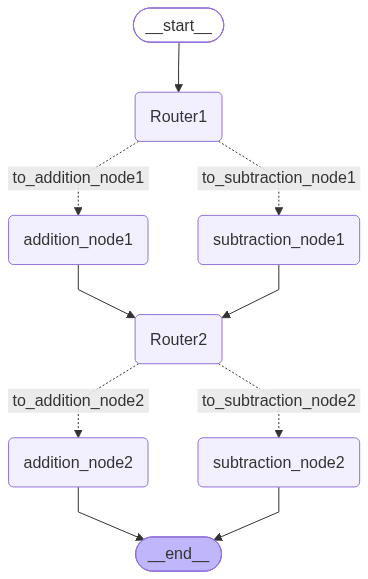

In [17]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [19]:
results = app.invoke({"number1":10, "operator1":"sub", "number2":5,
"number3":7, "operator2":"sum", "number4":2
})
print(results)
print(results["finalNumber1"])
print(results["finalNumber2"])

{'number1': 10, 'operator1': 'sub', 'number2': 5, 'number3': 7, 'operator2': 'sum', 'number4': 2, 'finalNumber1': 5, 'finalNumber2': 9}
5
9
